# 04. Modelagem com Árvores de Decisão

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**  
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 02 — Avaliação Comparativa de Modelos**

Este notebook desenvolve e avalia Árvores de Decisão para classificação de `Cardiovascular_Disease` e regressão de `Risk_Score`, conforme os requisitos da Seção 4 do enunciado.

A modelagem contempla a comparação de critérios de divisão, o ajuste de hiperparâmetros por `GridSearchCV`, a avaliação de desempenho e complexidade, a análise de *overfitting* e a visualização das árvores e de suas regras de decisão.

Na classificação, são comparados os critérios Gini e Entropia, utilizando o F1-score como métrica principal. Na regressão, são analisados os critérios `squared_error` e `friedman_mse`, considerando o RMSE como referência.

São mantidas as seis variáveis preditoras selecionadas na Atividade 01, a divisão de 80% para treinamento e 20% para teste e a semente aleatória `random_state=42`.

O pré-processamento é incorporado aos `Pipelines` e ajustado exclusivamente aos dados de treinamento, inclusive durante a validação cruzada de cinco folds, evitando *data leakage*.

Ao final, são selecionados e salvos os modelos ajustados para utilização nas análises comparativas posteriores.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

A execução pressupõe que a pasta `projeto-cardiovascular-ia-02` esteja localizada em `Meu Drive`, conforme as instruções disponíveis no `README.md` da Atividade 02.

O código verifica a existência do dataset e prepara o ambiente para a execução das etapas seguintes.

In [ ]:
from google.colab import drive
from pathlib import Path
import os
import sys

drive.mount("/content/drive")

PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-02")

ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), "Dataset original não encontrado!"

os.chdir(PROJETO / "notebooks")

if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

print("Projeto localizado em:", PROJETO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-02


## 1. Preparação dos dados e protocolo experimental

In [ ]:
import importlib
import src.pipeline_data as pipeline_data

# Recarrega o módulo, caso a versão antiga esteja em memória
importlib.reload(pipeline_data)

# Confere se estamos utilizando a versão corrigida
print("Features selecionadas:")
print(pipeline_data.FEATURES_MODELO)

# Divisão a partir do CSV original
(
    X_train,
    X_test,
    y_train_c,
    y_test_c,
    y_train_r,
    y_test_r,
    feat_cols
) = pipeline_data.carregar_e_dividir_dados_sem_leakage(
    "../data/raw/cardiovascular_disease_prediction.csv"
)

print("\nDimensão do treinamento:", X_train.shape)
print("Dimensão do teste:", X_test.shape)

print("\nProporção de positivos no treinamento:", y_train_c.mean())

print("\nValores ausentes:")
print("Treinamento:", X_train.isna().sum().sum())
print("Teste:", X_test.isna().sum().sum())
print("\nVerificação do Risk_Score no treinamento:")
print("Valores iguais a zero:", (y_train_r == 0).sum())
print("Valores negativos:", (y_train_r < 0).sum())
print("Valor mínimo:", y_train_r.min())

Features selecionadas:
('Diabetes', 'Hypertension', 'Chest_Pain', 'ECG_Result', 'Blood_Glucose', 'Blood_Pressure_Systolic')

Dimensão do treinamento: (16000, 6)
Dimensão do teste: (4000, 6)

Proporção de positivos no treinamento: 0.306

Valores ausentes:
Treinamento: 476
Teste: 124

Verificação do Risk_Score no treinamento:
Valores iguais a zero: 1
Valores negativos: 29
Valor mínimo: -1.61


## 2. Árvore de decisão para classificação

Treinamento de uma árvore irrestrita e ajuste de hiperparâmetros com validação cruzada estratificada de cinco folds, utilizando F1-score como métrica de seleção.

In [ ]:
import importlib
import src.models as modelos
import src.profiling as profiling
from sklearn.metrics import f1_score

importlib.reload(modelos)
importlib.reload(profiling)

# Treina e mede os recursos em uma única execução
resultado_c, medicao_treinamento_c = profiling.medir_treinamento(
    modelos.treinar_arvore_classificacao,
    X_train,
    y_train_c,
    cv=5,
    random_state=42
)

tempo_treinamento_c = medicao_treinamento_c["tempo_treino_s"]

# Modelos completos: pré-processamento + árvore
arvore_c = resultado_c["modelo_ajustado"]
arvore_c_irrestrita = resultado_c["modelo_irrestrito"]

# Avaliação somente no treinamento
f1_treino_ajustada = f1_score(
    y_train_c, arvore_c.predict(X_train)
)

f1_treino_irrestrita = f1_score(
    y_train_c, arvore_c_irrestrita.predict(X_train)
)

print("Melhores hiperparâmetros:")
print(resultado_c["melhores_parametros"])

print(f"\nF1 médio da validação cruzada: {resultado_c['melhor_score_cv']:.4f}")
print(f"Desvio padrão dos folds: {resultado_c['desvio_score_cv']:.4f}")
print(f"F1 no treinamento — árvore ajustada: {f1_treino_ajustada:.4f}")
print(f"F1 no treinamento — árvore irrestrita: {f1_treino_irrestrita:.4f}")

print(f"\nTempo total de treinamento e busca: {tempo_treinamento_c:.2f} segundos")

print(
    "Profundidade da árvore ajustada:",
    arvore_c.named_steps["modelo"].get_depth()
)

print(
    "Profundidade da árvore irrestrita:",
    arvore_c_irrestrita.named_steps["modelo"].get_depth()
)

Melhores hiperparâmetros:
{'modelo__ccp_alpha': 0.005, 'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5}

F1 médio da validação cruzada: 0.6349
Desvio padrão dos folds: 0.0057
F1 no treinamento — árvore ajustada: 0.6350
F1 no treinamento — árvore irrestrita: 0.8876

Tempo total de treinamento e busca: 71.11 segundos
Profundidade da árvore ajustada: 4
Profundidade da árvore irrestrita: 35


### 2.1 Comparação entre árvore ajustada e irrestrita

Avaliamos o desempenho das duas árvores por validação cruzada estratificada de cinco folds, comparando F1 no treinamento e na validação para investigar possíveis sinais de overfitting.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Validação cruzada da árvore irrestrita
cv_irrestrita = cross_validate(
    arvore_c_irrestrita,
    X_train,
    y_train_c,
    cv=cv_5,
    scoring="f1",
    return_train_score=True,
    n_jobs=2
)

comparacao_cv = pd.DataFrame({
    "Modelo": ["Árvore ajustada", "Árvore irrestrita"],
    "F1 médio treino": [
        resultado_c["score_treino_medio_cv"],
        cv_irrestrita["train_score"].mean()
    ],
    "F1 médio validação": [
        resultado_c["melhor_score_cv"],
        cv_irrestrita["test_score"].mean()
    ],
    "Desvio padrão validação": [
        resultado_c["desvio_score_cv"],
        cv_irrestrita["test_score"].std()
    ]
})

comparacao_cv["Gap treino - validação"] = (
    comparacao_cv["F1 médio treino"]
    - comparacao_cv["F1 médio validação"]
)

display(comparacao_cv.round(4))

,Modelo,F1 médio treino,F1 médio validação,Desvio padrão validação,Gap treino - validação
0,Árvore ajustada,0.6350,0.6349,0.0057,0.0000
1,Árvore irrestrita,0.9037,0.5109,0.0061,0.3928


### 2.2 Visualização e interpretação da árvore ajustada

A árvore ajustada será visualizada para identificar as variáveis utilizadas nas divisões, os critérios de decisão e os caminhos que levam às classificações.

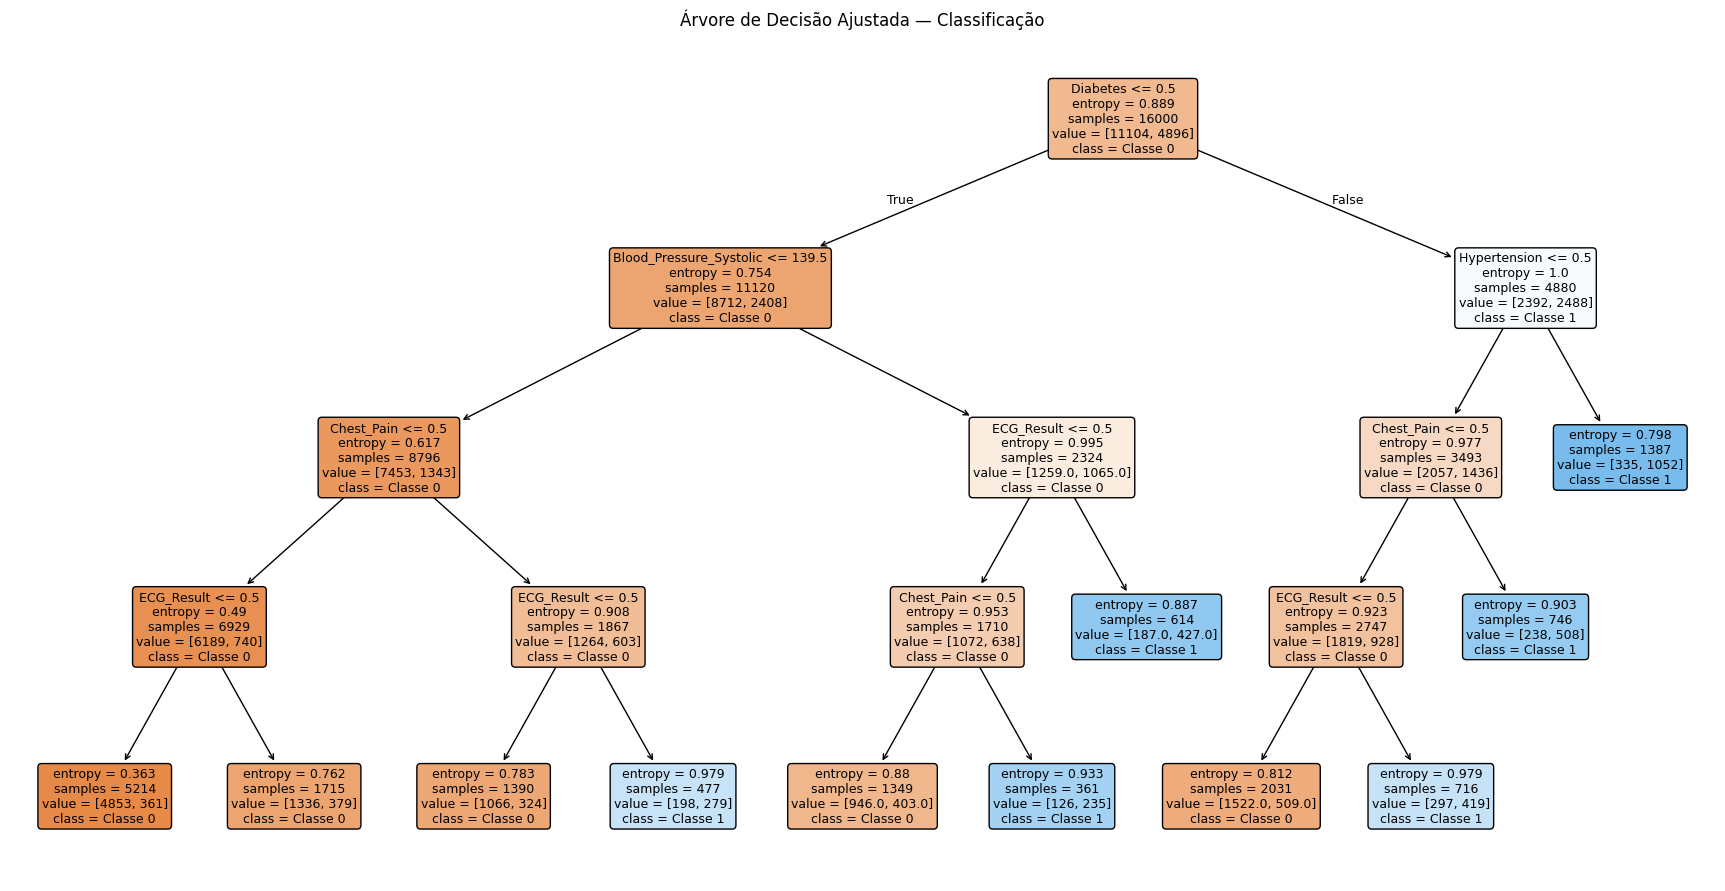


REGRAS DA ÁRVORE AJUSTADA:

|--- Diabetes <= 0.50
|   |--- Blood_Pressure_Systolic <= 139.50
|   |   |--- Chest_Pain <= 0.50
|   |   |   |--- ECG_Result <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- ECG_Result >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Chest_Pain >  0.50
|   |   |   |--- ECG_Result <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- ECG_Result >  0.50
|   |   |   |   |--- class: 1
|   |--- Blood_Pressure_Systolic >  139.50
|   |   |--- ECG_Result <= 0.50
|   |   |   |--- Chest_Pain <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- Chest_Pain >  0.50
|   |   |   |   |--- class: 1
|   |   |--- ECG_Result >  0.50
|   |   |   |--- class: 1
|--- Diabetes >  0.50
|   |--- Hypertension <= 0.50
|   |   |--- Chest_Pain <= 0.50
|   |   |   |--- ECG_Result <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- ECG_Result >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Chest_Pain >  0.50
|   |   |   |--- class: 1
|   |--- Hypertension >  0.50
|   |   |

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

# Extrair o pré-processador e a árvore ajustada
preprocessador_c = arvore_c.named_steps["preprocessamento"]
modelo_arvore_c = arvore_c.named_steps["modelo"]

# Recuperar os nomes corretos das seis variáveis
nomes_variaveis = list(
    preprocessador_c.get_feature_names_out()
)

# Visualizar a árvore
plt.figure(figsize=(22, 11))

plot_tree(
    modelo_arvore_c,
    feature_names=nomes_variaveis,
    class_names=["Classe 0", "Classe 1"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árvore de Decisão Ajustada — Classificação")

plt.savefig(
    PROJETO / "reports/figures/arvore_decisao_classificacao.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Extrair as decisões em formato textual
print("\nREGRAS DA ÁRVORE AJUSTADA:\n")

print(
    export_text(
        modelo_arvore_c,
        feature_names=nomes_variaveis,
        decimals=2
    )
)

### 2.3 Interpretação de três regras da árvore de classificação

Foram selecionados três caminhos da árvore ajustada para interpretação e comparação com o Sistema Especialista.

**Regra 1 — Classificação positiva**

SE `Diabetes = 1` E `Hypertension = 1`, ENTÃO `Cardiovascular_Disease = 1`.

A árvore classifica como positivo um registro que apresenta simultaneamente diabetes e hipertensão, sem exigir outras condições. Essa decisão coincide com a regra **RC06** do Sistema Especialista, embora a ordem de prioridade deste possa fazer outra regra positiva prevalecer.

**Regra 2 — Classificação negativa**

SE `Diabetes = 0` E `Blood_Pressure_Systolic ≤ 139,5` E `Chest_Pain = 0` E `ECG_Result = 0`, ENTÃO `Cardiovascular_Disease = 0`.

A árvore identifica uma combinação associada à classe negativa no treinamento. Essa decisão apresenta semelhança com a regra **RC04** do Sistema Especialista, mas não é equivalente: a RC04 também exige ausência de hipertensão, enquanto a árvore utiliza um limite numérico de pressão sistólica.

**Regra 3 — Classificação positiva**

SE `Diabetes = 0` E `Blood_Pressure_Systolic ≤ 139,5` E `Chest_Pain = 1` E `ECG_Result = 1`, ENTÃO `Cardiovascular_Disease = 1`.

Nesse caminho, a presença simultânea de dor no peito e alteração no ECG conduz à classificação positiva. O resultado coincide com a regra **RC08** do Sistema Especialista, que utiliza essa mesma associação.

**Comparação:** as duas abordagens identificaram algumas associações semelhantes. Entretanto, enquanto o Sistema Especialista utiliza regras previamente definidas e ordenadas, a Árvore de Decisão aprende automaticamente suas condições, seus limites e sua estrutura a partir dos dados de treinamento.

Os caminhos extraídos representam padrões estatísticos do dataset e não devem ser interpretados como critérios clínicos de diagnóstico.

## 3. Árvore de Decisão para Regressão

Nesta etapa, serão treinadas duas árvores para prever `Risk_Score`: uma irrestrita e outra ajustada por validação cruzada de cinco folds.

A busca de hiperparâmetros compara os critérios `squared_error` e `friedman_mse`, utilizando o RMSE como métrica de seleção. O pré-processamento ocorre dentro de cada fold, evitando vazamento de dados.

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Treinamento e medição de recursos em uma única execução
resultado_r, medicao_treinamento_r = profiling.medir_treinamento(
    modelos.treinar_arvore_regressao,
    X_train,
    y_train_r,
    cv=5,
    random_state=42
)

tempo_treinamento_r = medicao_treinamento_r["tempo_treino_s"]

# Modelos completos: pré-processamento + árvore
arvore_r = resultado_r["modelo_ajustado"]
arvore_r_irrestrita = resultado_r["modelo_irrestrito"]

# Previsões somente no treinamento
pred_r_ajustada = arvore_r.predict(X_train)
pred_r_irrestrita = arvore_r_irrestrita.predict(X_train)

# RMSE no treinamento
rmse_treino_ajustada = np.sqrt(
    mean_squared_error(y_train_r, pred_r_ajustada)
)

rmse_treino_irrestrita = np.sqrt(
    mean_squared_error(y_train_r, pred_r_irrestrita)
)

print("Melhores hiperparâmetros:")
print(resultado_r["melhores_parametros"])

print(f"\nRMSE médio da validação cruzada: {resultado_r['melhor_score_cv']:.4f}")
print(f"Desvio padrão dos folds: {resultado_r['desvio_score_cv']:.4f}")

print(f"\nRMSE no treinamento — árvore ajustada: {rmse_treino_ajustada:.4f}")
print(f"RMSE no treinamento — árvore irrestrita: {rmse_treino_irrestrita:.4f}")

print(f"\nTempo total de treinamento e busca: {tempo_treinamento_r:.2f} segundos")

print(
    "Profundidade da árvore ajustada:",
    arvore_r.named_steps["modelo"].get_depth()
)

print(
    "Profundidade da árvore irrestrita:",
    arvore_r_irrestrita.named_steps["modelo"].get_depth()
)

Melhores hiperparâmetros:
{'modelo__ccp_alpha': 0.001, 'modelo__criterion': 'squared_error', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 20}

RMSE médio da validação cruzada: 2.9834
Desvio padrão dos folds: 0.0398

RMSE no treinamento — árvore ajustada: 2.9681
RMSE no treinamento — árvore irrestrita: 1.6213

Tempo total de treinamento e busca: 20.41 segundos
Profundidade da árvore ajustada: 5
Profundidade da árvore irrestrita: 32


### 3.1 Comparação entre árvore ajustada e irrestrita

As árvores serão comparadas por validação cruzada de cinco folds, utilizando RMSE no treinamento e na validação para investigar possíveis sinais de overfitting.

In [ ]:
import pandas as pd
from sklearn.model_selection import KFold, cross_validate

cv_5_r = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Validar a árvore irrestrita somente no treinamento
cv_irrestrita_r = cross_validate(
    arvore_r_irrestrita,
    X_train,
    y_train_r,
    cv=cv_5_r,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    n_jobs=2
)

# Converter scores negativos em RMSE positivo
rmse_cv_treino_irrestrita = -cv_irrestrita_r["train_score"]
rmse_cv_validacao_irrestrita = -cv_irrestrita_r["test_score"]

comparacao_regressao = pd.DataFrame({
    "Modelo": ["Árvore ajustada", "Árvore irrestrita"],
    "RMSE médio treino": [
        resultado_r["score_treino_medio_cv"],
        rmse_cv_treino_irrestrita.mean()
    ],
    "RMSE médio validação": [
        resultado_r["melhor_score_cv"],
        rmse_cv_validacao_irrestrita.mean()
    ],
    "Desvio padrão validação": [
        resultado_r["desvio_score_cv"],
        rmse_cv_validacao_irrestrita.std(ddof=0)
    ]
})

comparacao_regressao["Gap validação - treino"] = (
    comparacao_regressao["RMSE médio validação"]
    - comparacao_regressao["RMSE médio treino"]
)

display(comparacao_regressao.round(4))

,Modelo,RMSE médio treino,RMSE médio validação,Desvio padrão validação,Gap validação - treino
0,Árvore ajustada,2.9641,2.9834,0.0398,0.0194
1,Árvore irrestrita,1.5104,4.1147,0.0597,2.6043


### 3.2 Visualização da árvore ajustada de regressão

A árvore ajustada será visualizada para identificar as variáveis e os limites utilizados na previsão de `Risk_Score`. Para facilitar a leitura, serão exibidos apenas os três primeiros níveis da estrutura.

Profundidade da árvore: 5
Número de folhas: 32


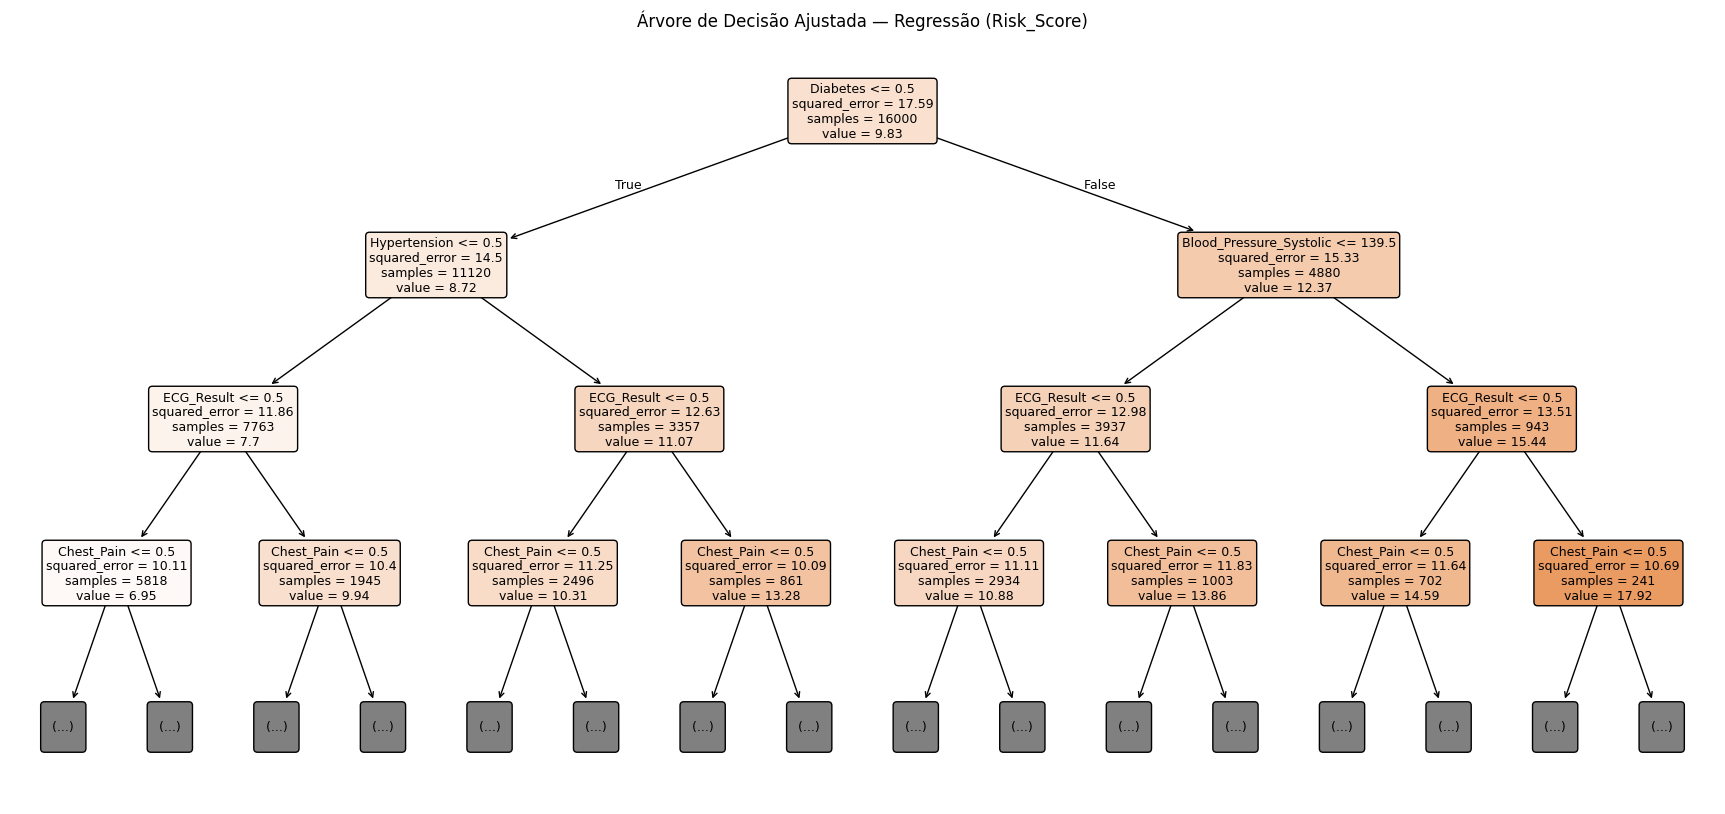


ESTRUTURA TEXTUAL DA ÁRVORE:

|--- Diabetes <= 0.50
|   |--- Hypertension <= 0.50
|   |   |--- ECG_Result <= 0.50
|   |   |   |--- Chest_Pain <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Chest_Pain >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- ECG_Result >  0.50
|   |   |   |--- Chest_Pain <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Chest_Pain >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- Hypertension >  0.50
|   |   |--- ECG_Result <= 0.50
|   |   |   |--- Chest_Pain <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Chest_Pain >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- ECG_Result >  0.50
|   |   |   |--- Chest_Pain <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Chest_Pain >  0.50
|   |   |   |   |--- truncated branch of depth 2
|--- Diabetes >  0.50
|   |--- Blood_Pressure_Systolic <= 139.50
|   |   |--- E

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

# Extrair os componentes do Pipeline
preprocessador_r = arvore_r.named_steps["preprocessamento"]
modelo_arvore_r = arvore_r.named_steps["modelo"]

# Nomes das variáveis após o pré-processamento
nomes_variaveis_r = list(
    preprocessador_r.get_feature_names_out()
)

print("Profundidade da árvore:", modelo_arvore_r.get_depth())
print("Número de folhas:", modelo_arvore_r.get_n_leaves())

# Visualizar os três primeiros níveis
plt.figure(figsize=(22, 10))

plot_tree(
    modelo_arvore_r,
    feature_names=nomes_variaveis_r,
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)

plt.title("Árvore de Decisão Ajustada — Regressão (Risk_Score)")

plt.savefig(
    PROJETO / "reports/figures/arvore_decisao_regressao.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Exibir as decisões em formato textual
print("\nESTRUTURA TEXTUAL DA ÁRVORE:\n")

print(
    export_text(
        modelo_arvore_r,
        feature_names=nomes_variaveis_r,
        max_depth=3,
        decimals=2
    )
)

### 3.3 Interpretação das regras da árvore de regressão

Serão examinados três caminhos completos da árvore ajustada, representando previsões menores, intermediárias e maiores de Risk_Score.

In [ ]:
# Extrair caminhos completos até as folhas da árvore
estrutura = modelo_arvore_r.tree_
caminhos = []

def extrair_caminhos(no, condicoes):
    esquerda = estrutura.children_left[no]
    direita = estrutura.children_right[no]

    if esquerda == -1:  # Chegamos a uma folha
        caminhos.append({
            "condicoes": condicoes,
            "previsao": float(estrutura.value[no, 0, 0]),
            "amostras": int(estrutura.n_node_samples[no])
        })
        return

    variavel = nomes_variaveis_r[estrutura.feature[no]]
    limite = estrutura.threshold[no]

    extrair_caminhos(
        esquerda,
        condicoes + [f"{variavel} <= {limite:.2f}"]
    )

    extrair_caminhos(
        direita,
        condicoes + [f"{variavel} > {limite:.2f}"]
    )

extrair_caminhos(0, [])

# Ordenar folhas pelo Risk_Score estimado
caminhos.sort(key=lambda x: x["previsao"])

selecionados = [
    ("Menor previsão", caminhos[0]),
    ("Previsão intermediária", caminhos[len(caminhos) // 2]),
    ("Maior previsão", caminhos[-1])
]

print("Total de folhas:", len(caminhos))

for titulo, caminho in selecionados:
    print(f"\n{titulo}")
    print("SE " + " E ".join(caminho["condicoes"]))
    print(f"ENTÃO Risk_Score estimado = {caminho['previsao']:.4f}")
    print(f"Registros de treinamento na folha: {caminho['amostras']}")

Total de folhas: 32

Menor previsão
SE Diabetes <= 0.50 E Hypertension <= 0.50 E ECG_Result <= 0.50 E Chest_Pain <= 0.50 E Blood_Glucose <= 112.50
ENTÃO Risk_Score estimado = 6.2668
Registros de treinamento na folha: 3692

Previsão intermediária
SE Diabetes <= 0.50 E Hypertension <= 0.50 E ECG_Result > 0.50 E Chest_Pain > 0.50 E Blood_Pressure_Systolic > 124.50
ENTÃO Risk_Score estimado = 12.7227
Registros de treinamento na folha: 162

Maior previsão
SE Diabetes > 0.50 E Blood_Pressure_Systolic > 139.50 E ECG_Result > 0.50 E Chest_Pain > 0.50 E Blood_Glucose > 135.00
ENTÃO Risk_Score estimado = 20.9607
Registros de treinamento na folha: 30


**Análise das regras extraídas**

A árvore ajustada de regressão apresentou 32 folhas. Foram selecionados três caminhos completos, correspondentes à menor previsão (6,2668), a uma previsão intermediária (12,7227) e à maior previsão (20,9607) de `Risk_Score`.

A menor previsão está associada à ausência de diabetes, hipertensão, alteração no ECG e dor no peito, juntamente com glicose de até 112,5 mg/dL.

A previsão intermediária ocorre em registros sem diabetes ou hipertensão, mas com alteração no ECG, dor no peito e pressão sistólica superior a 124,5 mmHg.

A maior previsão combina diabetes, alteração no ECG, dor no peito, pressão sistólica superior a 139,5 mmHg e glicose superior a 135 mg/dL.

As folhas selecionadas contêm, respectivamente, 3.692, 162 e 30 registros de treinamento. A menor quantidade de exemplos na folha de maior previsão recomenda cautela quanto à sua generalização.

Diferentemente do Sistema Especialista de classificação, a árvore de regressão estima valores numéricos de `Risk_Score`. Suas condições foram aprendidas automaticamente a partir dos dados e não constituem critérios clínicos validados.

### 3.4 Comparação dos critérios de divisão

Para cada critério, apresenta-se o melhor resultado obtido na validação cruzada, considerando as combinações de hiperparâmetros avaliadas no GridSearchCV.

In [ ]:
import pandas as pd

comparacao_criterios = []

for tarefa, resultado, criterios in [
    ("Classificação", resultado_c, ["gini", "entropy"]),
    ("Regressão", resultado_r, ["squared_error", "friedman_mse"])
]:
    resultados_cv = pd.DataFrame(
        resultado["grid_cv"].cv_results_
    )

    for criterio in criterios:
        dados = resultados_cv[
            resultados_cv["param_modelo__criterion"] == criterio
        ]

        melhor_score = dados["mean_test_score"].max()

        comparacao_criterios.append({
            "Tarefa": tarefa,
            "Critério": criterio,
            "Métrica": "F1" if tarefa == "Classificação" else "RMSE",
            "Melhor resultado CV": (
                melhor_score if tarefa == "Classificação"
                else -melhor_score
            )
        })

display(pd.DataFrame(comparacao_criterios).round(4))

,Tarefa,Critério,Métrica,Melhor resultado CV
0,Classificação,gini,F1,0.6280
1,Classificação,entropy,F1,0.6349
2,Regressão,squared_error,RMSE,2.9834
3,Regressão,friedman_mse,RMSE,2.9834


**Análise dos critérios de divisão**

Na classificação, o critério `entropy` apresentou o melhor F1-score médio na validação cruzada (0,6349), superando o critério `gini` (0,6280).

Na regressão, os critérios `squared_error` e `friedman_mse` apresentaram RMSE de validação cruzada praticamente idêntico (2,9834, considerando quatro casas decimais). Essa proximidade é coerente com o fato de ambos utilizarem o erro quadrático, embora o `friedman_mse` empregue a medida de melhoria de Friedman para avaliar as divisões. O critério `squared_error` foi selecionado pelo `GridSearchCV`, sem apresentar vantagem relevante de desempenho neste experimento.

Os resultados demonstram que dois critérios foram avaliados para cada tarefa e que os modelos foram selecionados por validação cruzada, sem utilizar o conjunto de teste.

**Observações sobre os hiperparâmetros e a poda**

Na classificação, o `GridSearchCV` selecionou `max_depth=5` e `ccp_alpha=0.005`. Entretanto, a árvore resultante apresentou profundidade 4, em consequência do controle de complexidade. Algumas folhas podem prever a mesma classe, mas apresentar probabilidades diferentes, relevantes para métricas como ROC-AUC.

Na regressão, foi selecionado `max_depth=5`, valor mínimo da grade pesquisada. Essa condição representa uma limitação da abrangência da busca, embora os resultados da validação cruzada tenham apresentado boa estabilidade.

Os modelos definitivos não foram modificados após a avaliação no conjunto de teste.

## 4. Complexidade dos modelos

Nesta etapa, são comparadas as características estruturais das árvores ajustadas e irrestritas, considerando profundidade, número de nós, número de folhas e tamanho serializado em disco.

Esses indicadores permitem avaliar como o controle de complexidade influencia o tamanho dos modelos.




In [ ]:
import pandas as pd
import src.profiling as profiling
import importlib

importlib.reload(profiling)

# Modelos já treinados anteriormente
arvores = {
    "Classificação — ajustada": arvore_c,
    "Classificação — irrestrita": arvore_c_irrestrita,
    "Regressão — ajustada": arvore_r,
    "Regressão — irrestrita": arvore_r_irrestrita
}

resultados_complexidade = []

for nome, pipeline in arvores.items():

    # Recuperar a árvore dentro do Pipeline
    modelo = pipeline.named_steps["modelo"]

    # Medir tamanho do Pipeline completo serializado
    tamanho_kb = profiling.obter_tamanho_modelo_disco(
        pipeline
    )

    resultados_complexidade.append({
        "Modelo": nome,
        "Profundidade": modelo.get_depth(),
        "Número de nós": modelo.tree_.node_count,
        "Número de folhas": modelo.get_n_leaves(),
        "Tamanho em disco (KB)": tamanho_kb
    })

tabela_complexidade = pd.DataFrame(
    resultados_complexidade
)

display(tabela_complexidade.round(2))

,Modelo,Profundidade,Número de nós,Número de folhas,Tamanho em disco (KB)
0,Classificação — ajustada,4,21,11,6.14
1,Classificação — irrestrita,35,9781,4891,768.63
2,Regressão — ajustada,5,63,32,8.79
3,Regressão — irrestrita,32,22559,11280,1590.54


## 5. Eficiência computacional da inferência

A inferência das árvores ajustadas de classificação e regressão foi avaliada em 30 repetições, utilizando 4.000 registros do treinamento. O pré-processamento foi realizado antes da cronometragem, seguindo o protocolo utilizado no Sistema Especialista.

Foram registrados tempo médio, desvio padrão, tempo por amostra, vazão, pico de memória Python e estimativas de energia e emissões de CO₂.

In [ ]:
import importlib
import pandas as pd
import src.profiling as profiling

importlib.reload(profiling)

# Mesmos registros selecionados no benchmark do Notebook 03
indices_benchmark = X_train.sample(
    n=4000,
    random_state=42
).index

X_benchmark = X_train.loc[indices_benchmark]

resultados_eficiencia = []
medicoes_individuais = []

modelos_benchmark = {
    "Árvore de classificação": arvore_c,
    "Árvore de regressão": arvore_r
}

for nome, pipeline in modelos_benchmark.items():

    # Pré-processamento fora da cronometragem
    X_preparado = pipeline.named_steps[
        "preprocessamento"
    ].transform(X_benchmark)

    modelo = pipeline.named_steps["modelo"]

    resultado = profiling.medir_inferencia(
        modelo.predict,
        X_preparado,
        n_rep=30,
        n_aquecimento=1,
        retornar_detalhes=True
    )

    energia = profiling.estimar_energia_carbono(
        resultado["tempo_medio_s"]
    )

    resultados_eficiencia.append({
        "Modelo": nome,
        "Tempo médio (s)": resultado["tempo_medio_s"],
        "Desvio padrão (s)": resultado["tempo_desvio_s"],
        "Tempo/amostra (ms)": resultado["tempo_por_amostra_ms"],
        "Vazão (amostras/s)": resultado["vazao_amostras_s"],
        "Pico memória Python (KB)": resultado["pico_memoria_kb"],
        "Energia estimada (kWh)": energia["energia_kwh"],
        "Emissão estimada (g CO2)": energia["emissao_co2_g"]
    })

    for medicao in resultado["detalhes"]:
        medicoes_individuais.append({
            "modelo": nome,
            **medicao
        })

tabela_eficiencia = pd.DataFrame(resultados_eficiencia)

display(
    tabela_eficiencia.style.format({
        "Tempo médio (s)": "{:.6f}",
        "Desvio padrão (s)": "{:.6f}",
        "Tempo/amostra (ms)": "{:.8f}",
        "Vazão (amostras/s)": "{:,.2f}",
        "Pico memória Python (KB)": "{:.2f}",
        "Energia estimada (kWh)": "{:.6e}",
        "Emissão estimada (g CO2)": "{:.6e}"
    })
)

# Preservar as 30 medições de cada árvore
arquivo_saida = (
    PROJETO / "logs/medicoes_inferencia_arvores.csv"
)

pd.DataFrame(medicoes_individuais).to_csv(
    arquivo_saida,
    index=False
)

print("\nMedições individuais salvas em:", arquivo_saida)

,Modelo,Tempo médio (s),Desvio padrão (s),Tempo/amostra (ms),Vazão (amostras/s),Pico memória Python (KB),Energia estimada (kWh),Emissão estimada (g CO2)
0,Árvore de classificação,0.001624,0.000063,0.00040588,"2,463,797.02",219.69,2.029388e-08,9.294597e-07
1,Árvore de regressão,0.001550,0.000059,0.00038748,"2,580,755.77",158.11,1.937417e-08,8.873370e-07



Medições individuais salvas em: /content/drive/MyDrive/projeto-cardiovascular-ia-02/logs/medicoes_inferencia_arvores.csv


### 5.1 Eficiência computacional do treinamento

O treinamento das árvores de classificação e regressão foi medido considerando o ajuste da árvore irrestrita e a busca de hiperparâmetros com validação cruzada.

Foram registrados o tempo total de execução, o pico de alocações de memória Python e as estimativas de energia e emissões de CO₂. A medição de memória utiliza `tracemalloc` e não representa o consumo total de RAM, especialmente dos processos paralelos da validação cruzada.

As medições são realizadas durante o treinamento nas seções 2 e 3 e reaproveitadas nesta seção, evitando a repetição da busca de hiperparâmetros.

In [ ]:
import pandas as pd

# Reutilizar as medições feitas nas seções 2 e 3
medicoes_treinamento = [
    ("Árvore de classificação", medicao_treinamento_c),
    ("Árvore de regressão", medicao_treinamento_r)
]

resultados_treinamento = []

for nome, medicao in medicoes_treinamento:

    energia = profiling.estimar_energia_carbono(
        medicao["tempo_treino_s"]
    )

    resultados_treinamento.append({
        "Modelo": nome,
        "Tempo total (s)": medicao["tempo_treino_s"],
        "Pico memória Python (KB)": medicao["pico_memoria_treino_kb"],
        "Energia estimada (kWh)": energia["energia_kwh"],
        "Emissão estimada (g CO2)": energia["emissao_co2_g"]
    })

tabela_treinamento = pd.DataFrame(resultados_treinamento)

display(
    tabela_treinamento.style.format({
        "Tempo total (s)": "{:.4f}",
        "Pico memória Python (KB)": "{:.2f}",
        "Energia estimada (kWh)": "{:.8e}",
        "Emissão estimada (g CO2)": "{:.8e}"
    })
)

,Modelo,Tempo total (s),Pico memória Python (KB),Energia estimada (kWh),Emissão estimada (g CO2)
0,Árvore de classificação,71.1148,3576.64,8.88935370e-04,4.07132400e-02
1,Árvore de regressão,20.4059,3257.92,2.55073202e-04,1.16823526e-02


**Observações metodológicas**

Os tempos de treinamento apresentados incluem a busca de hiperparâmetros com validação cruzada, o ajuste final selecionado pelo GridSearchCV e o treinamento da árvore irrestrita.

A medição utiliza `tracemalloc`, que permite acompanhar alocações de memória Python, mas pode aumentar o tempo de execução. Por isso, os tempos desta seção não são diretamente comparáveis aos cronometrados anteriormente sem esse monitoramento.

O pico de memória não representa todo o consumo de RAM, especialmente dos processos paralelos utilizados pela validação cruzada. As estimativas de energia e CO₂ foram calculadas a partir dos tempos medidos, considerando potência assumida de 45 W e fator de emissão de 45,8 g CO₂/kWh.

### 5.2 Tempo de ajuste isolado dos modelos finais

O tempo de ajuste das árvores selecionadas é medido separadamente do GridSearchCV. Cada Pipeline é clonado e treinado cinco vezes com os hiperparâmetros já definidos, utilizando somente o conjunto de treinamento.

São apresentados a média e o desvio padrão dos tempos de execução. Essa medição inclui o pré-processamento e o ajuste do modelo, mas exclui a busca de hiperparâmetros.

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone

resultados_ajuste = []

experimentos = [
    ("Árvore de classificação", arvore_c, y_train_c),
    ("Árvore de regressão", arvore_r, y_train_r)
]

for nome, pipeline, y in experimentos:
    tempos = []

    for _ in range(5):
        modelo_temporario = clone(pipeline)

        inicio = time.perf_counter()
        modelo_temporario.fit(X_train, y)
        tempo = time.perf_counter() - inicio

        tempos.append(tempo)

    resultados_ajuste.append({
        "Modelo": nome,
        "Repetições": len(tempos),
        "Tempo médio ajuste (s)": np.mean(tempos),
        "Desvio padrão (s)": np.std(tempos, ddof=1)
    })

tabela_ajuste_isolado = pd.DataFrame(resultados_ajuste)

display(tabela_ajuste_isolado.round(6))

,Modelo,Repetições,Tempo médio ajuste (s),Desvio padrão (s)
0,Árvore de classificação,5,0.068826,0.005444
1,Árvore de regressão,5,0.066891,0.002711


## 6. Avaliação final das árvores de decisão

As árvores ajustadas de classificação e regressão são avaliadas no conjunto de teste reservado, sem novos ajustes de hiperparâmetros. Os resultados serão comparados com os do treinamento para analisar seu desempenho e generalização.

In [ ]:
import importlib
import pandas as pd
import src.metrics as metricas

importlib.reload(metricas)

# CLASSIFICAÇÃO — árvore ajustada
pred_c_treino = arvore_c.predict(X_train)
pred_c_teste = arvore_c.predict(X_test)

prob_c_treino = arvore_c.predict_proba(X_train)[:, 1]
prob_c_teste = arvore_c.predict_proba(X_test)[:, 1]

mc_treino = metricas.calcular_metricas_classificacao(
    y_train_c, pred_c_treino, prob_c_treino
)

mc_teste = metricas.calcular_metricas_classificacao(
    y_test_c, pred_c_teste, prob_c_teste
)

indicadores_c = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC", "PR-AUC",
    "Average_Precision"
]

tabela_c = pd.DataFrame({
    "Treinamento": [mc_treino[k] for k in indicadores_c],
    "Teste": [mc_teste[k] for k in indicadores_c]
}, index=indicadores_c)

print("CLASSIFICAÇÃO — ÁRVORE AJUSTADA")
display(tabela_c.round(4))

print("\nMatriz de confusão — TESTE")
display(pd.DataFrame(
    mc_teste["Confusion_Matrix"],
    index=["Real 0", "Real 1"],
    columns=["Previsto 0", "Previsto 1"]
))

# REGRESSÃO — árvore ajustada
pred_r_treino = arvore_r.predict(X_train)
pred_r_teste = arvore_r.predict(X_test)

mr_treino = metricas.calcular_metricas_regressao(
    y_train_r, pred_r_treino
)

mr_teste = metricas.calcular_metricas_regressao(
    y_test_r, pred_r_teste
)

indicadores_r = [
    "MAE", "MSE", "RMSE", "MAPE", "R2", "MedAE"
]

tabela_r = pd.DataFrame({
    "Treinamento": [mr_treino[k] for k in indicadores_r],
    "Teste": [mr_teste[k] for k in indicadores_r]
}, index=indicadores_r)

print("\nREGRESSÃO — ÁRVORE AJUSTADA")
display(
    tabela_r.style.format(
        lambda valor: (
            f"{valor:.3e}" if abs(valor) >= 1e6
            else f"{valor:.4f}"
        )
    )
)

print("\nGaps de generalização:")
print(
    "F1 classificação:",
    round(mc_treino["F1-score"] - mc_teste["F1-score"], 4)
)
print(
    "RMSE regressão:",
    round(mr_teste["RMSE"] - mr_treino["RMSE"], 4)
)

CLASSIFICAÇÃO — ÁRVORE AJUSTADA


,Treinamento,Teste
Accuracy,0.7902,0.7795
Precision,0.6789,0.6583
Recall,0.5964,0.5809
F1-score,0.6350,0.6172
ROC-AUC,0.8040,0.7842
PR-AUC,0.6649,0.6562
Average_Precision,0.6203,0.6121



Matriz de confusão — TESTE


,Previsto 0,Previsto 1
Real 0,2407,369
Real 1,513,711



REGRESSÃO — ÁRVORE AJUSTADA


,Treinamento,Teste
MAE,2.3823,2.3836
MSE,8.8094,8.8252
RMSE,2.9681,2.9707
MAPE,1.764e+12,0.5952
R2,0.4991,0.4756
MedAE,2.0557,2.0181



Gaps de generalização:
F1 classificação: 0.0178
RMSE regressão: 0.0027


### 6.1 Comparação complementar — árvores irrestritas

As árvores sem restrições também são avaliadas no conjunto de teste para verificar a perda de generalização. Esses modelos foram definidos antes da avaliação final e não serão reajustados com base nos resultados.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, mean_squared_error

# Árvore irrestrita de classificação
f1_irrestrita_treino = f1_score(
    y_train_c,
    arvore_c_irrestrita.predict(X_train)
)

f1_irrestrita_teste = f1_score(
    y_test_c,
    arvore_c_irrestrita.predict(X_test)
)

# Árvore irrestrita de regressão
rmse_irrestrita_treino = np.sqrt(
    mean_squared_error(
        y_train_r,
        arvore_r_irrestrita.predict(X_train)
    )
)

rmse_irrestrita_teste = np.sqrt(
    mean_squared_error(
        y_test_r,
        arvore_r_irrestrita.predict(X_test)
    )
)

comparacao_irrestritas = pd.DataFrame([
    {
        "Modelo": "Classificação irrestrita",
        "Métrica": "F1",
        "Treinamento": f1_irrestrita_treino,
        "Teste": f1_irrestrita_teste,
        "Gap": f1_irrestrita_treino - f1_irrestrita_teste
    },
    {
        "Modelo": "Regressão irrestrita",
        "Métrica": "RMSE",
        "Treinamento": rmse_irrestrita_treino,
        "Teste": rmse_irrestrita_teste,
        "Gap": rmse_irrestrita_teste - rmse_irrestrita_treino
    }
])

display(comparacao_irrestritas.round(4))

,Modelo,Métrica,Treinamento,Teste,Gap
0,Classificação irrestrita,F1,0.8876,0.5218,0.3658
1,Regressão irrestrita,RMSE,1.6213,4.0296,2.4083


**Análise complementar de generalização**

As árvores irrestritas apresentaram evidências de *overfitting* tanto na validação cruzada quanto no teste. Na classificação, o F1 caiu de 0,8876 no treinamento para 0,5218 no teste, resultando em um gap de 0,3658. Na regressão, o RMSE aumentou de 1,6213 para 4,0296, com gap de 2,4083.

Esses resultados contrastam com a maior estabilidade das árvores ajustadas e reforçam a importância do controle de complexidade e da poda. As árvores irrestritas foram utilizadas apenas para análise comparativa, sem orientar novos ajustes após a avaliação do teste.

### Classificação dos modelos quanto à generalização

A comparação entre treinamento e teste permite analisar o comportamento das árvores ajustadas e irrestritas.

| Modelo | Indicador | Treinamento | Teste | Classificação |
|---|---|---:|---:|---|
| Classificação irrestrita | F1-score | 0,8876 | 0,5218 | Overfitting |
| Regressão irrestrita | RMSE | 1,6213 | 4,0296 | Overfitting |
| Classificação ajustada | F1-score | 0,6350 | 0,6172 | Bem ajustada quanto à generalização |
| Regressão ajustada | RMSE | 2,9681 | 2,9707 | Bem ajustada quanto à generalização |

**Árvores irrestritas:** apresentaram diferenças expressivas entre treinamento e teste, caracterizando *overfitting*. Isso indica que aprenderam particularidades dos dados de treinamento que não se generalizaram adequadamente para novos registros.

**Árvores ajustadas:** apresentaram diferenças pequenas entre treinamento e teste, evidenciando maior estabilidade e menor sobreajuste. Entretanto, o F1-score de 0,6172 na classificação e o R² de 0,4756 na regressão demonstram que o desempenho preditivo ainda é moderado.

**Underfitting:** não foi identificado de forma conclusiva. Embora o desempenho moderado das árvores ajustadas possa indicar limitações de capacidade preditiva, gaps pequenos, isoladamente, não comprovam nem descartam *underfitting*. Essa possibilidade deve ser considerada juntamente com as restrições de complexidade e as seis variáveis utilizadas.

Assim, as árvores ajustadas são classificadas como **bem ajustadas quanto à generalização**, com limitações de desempenho, enquanto as irrestritas apresentam **overfitting**.

### 6.2 Interpretação dos resultados e limitações

**Classificação.** A árvore ajustada apresentou Accuracy de 77,95%, F1-score de 0,6172 e Recall de 0,5809 no teste. O gap de F1 entre treinamento e teste foi de 0,0178, indicando estabilidade relativa. Entretanto, foram registrados 513 falsos negativos, correspondentes a 41,91% dos registros positivos.

Em comparação com o Sistema Especialista, a árvore obteve maior Accuracy e Precision, mas apresentou Recall e F1-score ligeiramente inferiores. Essa comparação evidencia a importância de considerar diferentes métricas na seleção dos modelos.

**Regressão.** A árvore ajustada obteve MAE de 2,3836, RMSE de 2,9707 e R² de 0,4756 no teste. O gap de RMSE de 0,0027 sugere boa estabilidade entre treinamento e teste, embora o desempenho preditivo permaneça moderado.

**Limitações do MAPE e dos dados**

O MAPE apresentou um valor extremamente elevado no treinamento (aproximadamente 1,76 × 10¹²), enquanto no teste foi de 0,5952. Essa diferença não deve ser interpretada como melhora da generalização, pois o MAPE é instável quando os valores reais se aproximam de zero. No conjunto de treinamento, a variável `Risk_Score` apresenta um valor igual a zero e 29 valores negativos, chegando a −1,61.

O valor zero provoca erros percentuais extremamente elevados na implementação do MAPE utilizada pelo scikit-learn, enquanto os valores negativos dificultam sua interpretação como percentual de risco. A presença de escores negativos também merece investigação quanto à definição e à validade da variável-alvo, sem que isso implique necessariamente um erro nos dados.

Por essas razões, o MAPE foi mantido para atender ao enunciado, mas as conclusões sobre desempenho e generalização da regressão foram baseadas principalmente em MAE, RMSE e R².

A validação cruzada demonstrou overfitting acentuado nas árvores irrestritas, enquanto as árvores ajustadas apresentaram diferenças pequenas entre treinamento e validação. Os resultados finais reforçam a importância do controle de profundidade e da poda.

As árvores foram selecionadas exclusivamente com dados de treinamento e validação cruzada. O conjunto de teste foi utilizado apenas na avaliação final, sem novos ajustes de hiperparâmetros.

A árvore de decisão ajustada também apresentou ROC-AUC de 0,7842, ligeiramente inferior ao resultado do Sistema Especialista (0,7909). Embora a árvore tenha obtido maior Accuracy e Precision, o Sistema Especialista apresentou Recall, F1-score e ROC-AUC superiores. Esses resultados demonstram que nenhum dos modelos foi melhor em todas as métricas. Considerando a importância de identificar corretamente os registros positivos, o Recall merece atenção especial, pois a árvore ajustada deixou de identificar 513 dos 1.224 registros positivos no conjunto de teste. Entretanto, a pequena diferença de ROC-AUC, isoladamente, não permite afirmar superioridade estatística entre os modelos.

### 6.3 Visualização dos resultados no conjunto de teste

São apresentadas a matriz de confusão da árvore ajustada de classificação e a distribuição dos resíduos da árvore ajustada de regressão. As figuras são salvas em `reports/figures`.

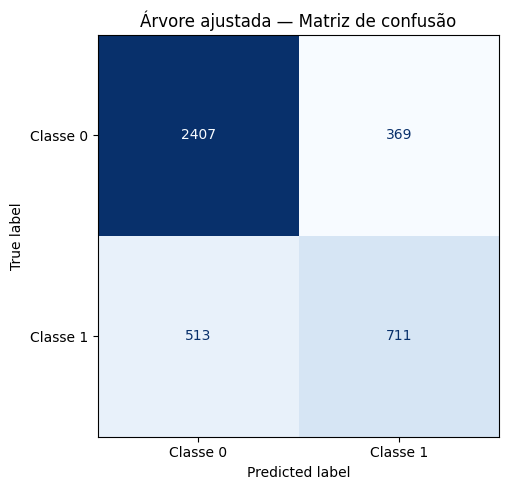

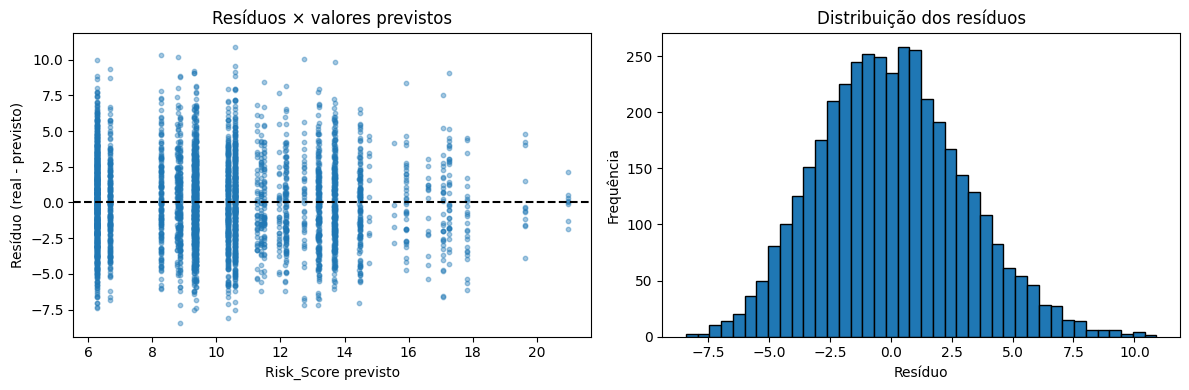

Figura de classificação: cm_decision_tree.png
Figura de regressão: residuos_decision_tree.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Diretório de saída
pasta_figuras = PROJETO / "reports" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

# 1. Matriz de confusão — classificação ajustada
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=mc_teste["Confusion_Matrix"],
    display_labels=["Classe 0", "Classe 1"]
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title("Árvore ajustada — Matriz de confusão")
fig.tight_layout()

arquivo_cm = pasta_figuras / "cm_decision_tree.png"
fig.savefig(arquivo_cm, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

# 2. Análise dos resíduos — regressão ajustada
residuos = np.asarray(y_test_r) - np.asarray(pred_r_teste)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].scatter(
    pred_r_teste,
    residuos,
    s=10,
    alpha=0.4
)

ax[0].axhline(0, color="black", linestyle="--")
ax[0].set_title("Resíduos × valores previstos")
ax[0].set_xlabel("Risk_Score previsto")
ax[0].set_ylabel("Resíduo (real - previsto)")

ax[1].hist(residuos, bins=40, edgecolor="black")
ax[1].set_title("Distribuição dos resíduos")
ax[1].set_xlabel("Resíduo")
ax[1].set_ylabel("Frequência")

fig.tight_layout()

arquivo_residuos = pasta_figuras / "residuos_decision_tree.png"
fig.savefig(arquivo_residuos, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Figura de classificação:", arquivo_cm.name)
print("Figura de regressão:", arquivo_residuos.name)

assert arquivo_cm.is_file()
assert arquivo_residuos.is_file()

## 7. Persistência dos modelos

As árvores ajustadas de classificação e regressão são salvas em formato Joblib, incluindo o Pipeline completo de pré-processamento e previsão. Os arquivos são recarregados para verificar a integridade dos modelos.

In [ ]:
from pathlib import Path
import joblib
import numpy as np
from sklearn.pipeline import Pipeline

# Pasta dos modelos no Google Drive
pasta_modelos = PROJETO / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Arquivos definitivos dos modelos ajustados
arquivo_clf = pasta_modelos / "decision_tree_clf.joblib"
arquivo_reg = pasta_modelos / "decision_tree_reg.joblib"

# Salvar os Pipelines completos
joblib.dump(arvore_c, arquivo_clf)
joblib.dump(arvore_r, arquivo_reg)

# Recarregar os arquivos salvos
modelo_clf_carregado = joblib.load(arquivo_clf)
modelo_reg_carregado = joblib.load(arquivo_reg)

# Conferir se os Pipelines foram preservados
assert isinstance(modelo_clf_carregado, Pipeline)
assert isinstance(modelo_reg_carregado, Pipeline)

# Verificar se as previsões permanecem iguais
amostra = X_train.head(20)

assert np.array_equal(
    arvore_c.predict(amostra),
    modelo_clf_carregado.predict(amostra)
)

assert np.allclose(
    arvore_r.predict(amostra),
    modelo_reg_carregado.predict(amostra)
)

print("Modelos salvos e carregados com sucesso!")

for arquivo in [arquivo_clf, arquivo_reg]:
    print(
        f"{arquivo.name}: "
        f"{arquivo.stat().st_size / 1024:.2f} KB"
    )

print("Verificação das previsões: OK")

Modelos salvos e carregados com sucesso!
decision_tree_clf.joblib: 6.14 KB
decision_tree_reg.joblib: 8.79 KB
Verificação das previsões: OK


## 8. Exportação dos resultados

As tabelas produzidas neste notebook são salvas em `reports/tables`, preservando os valores numéricos sem arredondamento. Os arquivos podem ser atualizados em novas execuções do notebook.

In [ ]:
from pathlib import Path
import pandas as pd

pasta_tabelas = PROJETO / "reports" / "tables"
pasta_tabelas.mkdir(parents=True, exist_ok=True)

# Preparar tabelas cujas métricas estão no índice
metricas_classificacao = (
    tabela_c.rename_axis("Métrica").reset_index()
)

metricas_regressao = (
    tabela_r.rename_axis("Métrica").reset_index()
)

# Matriz de confusão da árvore ajustada no teste
matriz_confusao = pd.DataFrame(
    mc_teste["Confusion_Matrix"],
    index=["Real 0", "Real 1"],
    columns=["Previsto 0", "Previsto 1"]
).rename_axis("Classe real").reset_index()

# Tabelas produzidas no Notebook 04
tabelas = {
    "arvores_cv_classificacao.csv": comparacao_cv,
    "arvores_cv_regressao.csv": comparacao_regressao,
    "arvores_criterios.csv": pd.DataFrame(comparacao_criterios),
    "arvores_complexidade.csv": tabela_complexidade,
    "arvores_inferencia.csv": tabela_eficiencia,
    "arvores_treinamento.csv": tabela_treinamento.merge(
    tabela_ajuste_isolado,
    on="Modelo",
    how="left",
    validate="one_to_one"
),
    "arvores_metricas_classificacao.csv": metricas_classificacao,
    "arvores_metricas_regressao.csv": metricas_regressao,
    "arvores_matriz_confusao.csv": matriz_confusao,
    "arvores_comparacao_irrestritas.csv": comparacao_irrestritas
}

# Salvar os CSVs, sobrescrevendo versões anteriores
for nome, tabela in tabelas.items():
    caminho = pasta_tabelas / nome

    tabela.to_csv(
        caminho,
        index=False,
        encoding="utf-8-sig",
        float_format="%.16g"
    )

    print(f"Salvo: {nome} ({len(tabela)} linhas)")

# Verificação básica dos arquivos
assert all(
    (pasta_tabelas / nome).is_file()
    for nome in tabelas
)

print("\nTotal de tabelas salvas:", len(tabelas))
print("Pasta:", pasta_tabelas)

Salvo: arvores_cv_classificacao.csv (2 linhas)
Salvo: arvores_cv_regressao.csv (2 linhas)
Salvo: arvores_criterios.csv (4 linhas)
Salvo: arvores_complexidade.csv (4 linhas)
Salvo: arvores_inferencia.csv (2 linhas)
Salvo: arvores_treinamento.csv (2 linhas)
Salvo: arvores_metricas_classificacao.csv (7 linhas)
Salvo: arvores_metricas_regressao.csv (6 linhas)
Salvo: arvores_matriz_confusao.csv (2 linhas)
Salvo: arvores_comparacao_irrestritas.csv (2 linhas)

Total de tabelas salvas: 10
Pasta: /content/drive/MyDrive/projeto-cardiovascular-ia-02/reports/tables
